# Capítulo 1 · Introducción

**Lectura:** pp. 13–30 del PDF; §§1.1–1.3. [Capítulo original](https://arxiv.org/html/2412.05265v5#Ch1).

**Idea central:** antes de elegir un algoritmo, hay que especificar qué observa el agente, qué puede hacer, qué intenta optimizar y qué desconoce.

## Resumen

En §1.1 Murphy presenta RL como parte de la toma de decisiones secuencial. El agente recibe observaciones, mantiene un estado interno y elige acciones mediante una política. Sus decisiones afectan a lo que verá y podrá hacer después. La información disponible, el estado real del mundo y los parámetros del agente son objetos distintos: aprender una política y actualizar una creencia no son la misma operación.

El objetivo habitual es maximizar retorno esperado. En tareas episódicas la interacción termina; en tareas continuas puede usarse un objetivo descontado o de recompensa media. El descuento controla cuánto pesan las consecuencias lejanas y, con recompensas acotadas y $\gamma<1$, hace finita la suma infinita. Cambiarlo puede cambiar la política óptima.

En §1.2 se ordenan varios modelos. Un MDP supone que el estado relevante es observado. Un POMDP permite observaciones parciales y necesita memoria o creencias sobre el estado oculto. Un estado de creencia resume probabilísticamente el historial cuando el modelo es conocido. También podemos mantener creencias sobre parámetros desconocidos: esto conecta la decisión con el aprendizaje del entorno.

Un bandit contextual tiene una decisión por contexto sin que la acción determine los contextos futuros; aun así, la acción determina qué recompensa observamos y qué aprendemos. Los MDP condicionados por metas permiten modificar el objetivo; los MDP contextuales permiten variar la tarea o dinámica entre episodios. La identificación del mejor brazo, la optimización bayesiana, el aprendizaje activo y hasta la elección de pasos de SGD se presentan como problemas relacionados de decisión e información.

En §1.3 aparece el mapa del resto del libro: aprender valores, aprender directamente políticas o aprender modelos para planificar. Esta clasificación es independiente de usar tablas o redes neuronales, y de aprender on-policy u off-policy. La observación parcial exige memoria; el desconocimiento del modelo exige exploración. Son problemas diferentes.

La recompensa tampoco es un detalle secundario. Una señal escasa dificulta aprender; una señal incorrecta puede producir un comportamiento eficaz para la puntuación e indeseable para la tarea. El shaping añade información, pero puede modificar el objetivo. El shaping basado en potencial tiene garantías bajo condiciones apropiadas. El capítulo termina con recomendaciones sobre variabilidad, agregación y evaluación experimental.

## Ecuaciones que debes poder explicar

$$
G_t=\sum_{k=0}^{T-t-1}\gamma^k r_{t+k},
\qquad
J(\pi)=\mathbb{E}_\pi[G_0].
$$

$G_t$ corresponde a una trayectoria; $J$ promedia sobre las trayectorias que producen política y entorno.

Para shaping basado en potencial:

$$
r'_t=r_t+\gamma\Phi(s_{t+1})-\Phi(s_t).
$$

La suma adicional se telescopa. Con potencial acotado en horizonte infinito descontado, o potencial terminal cero en episodios, añade un término independiente de las acciones desde un estado inicial fijo. Sin cuidar los estados terminales esa conclusión puede fallar.

## Experimento 1 · Futuro y memoria

**Pregunta:** ¿cambia la mejor decisión cuando modificamos el descuento o la información disponible?

**Hipótesis:** recibir 3 en $t=4$ supera recibir 1 ahora únicamente si $3\gamma^4>1$. Por otra parte, recordar una señal inicial permite resolver una tarea cuya observación final es ambigua.

El primer panel compara esos dos retornos para 201 valores de $\gamma$. El segundo genera un bit oculto equiprobable, lo revela al inicio y lo oculta antes de decidir. Compara una decisión aleatoria sin memoria con una política que recuerda la señal. Son políticas prescritas: este laboratorio ilustra la formulación, no entrena un agente.

~~~bash
uv run python -m experimentos.ejecutar --capitulo 1
~~~

**Qué medir:** punto de cruce de retornos y proporción de aciertos. Se realizan 20 réplicas de 1.000 episodios para la tarea de memoria.

**Qué observar:** el cruce está en $\gamma=(1/3)^{1/4}\approx0.760$; la política sin memoria ronda 50% y la que recuerda alcanza 100% en este entorno sin ruido. La igualdad en el umbral significa empate.

**Modificación:** cambia el retraso de cuatro a ocho pasos. Después introduce ruido en la señal inicial y comprueba que recordar ya no basta para acertar siempre.

**Límite:** no demuestra que una red recurrente vaya a aprender esa memoria. Solo demuestra que la información necesaria no está en la última observación.



## Para el grupo

1. ¿Qué habría que incluir en el estado de un robot para que la representación sea Markoviana?
2. ¿Puede un bandit necesitar exploración aunque sus acciones no cambien el mundo?
3. ¿Cómo distinguirías un fallo de aprendizaje de un fallo de recompensa?

**Conexión:** el capítulo 2 aprende a valorar consecuencias; el 3 aprende a actuar; el 4 aprende a predecirlas.


## Preparar la ejecución

Ejecuta todas las celdas en orden. El módulo contiene la implementación completa; la siguiente celda muestra su código. Cambia SEMILLA y REPLICAS para repetir. Los resultados del cuaderno se guardan en una carpeta separada.

In [1]:
from pathlib import Path
import sys
import json
import inspect
import subprocess
import importlib
from IPython.display import display, Image, Code

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / "experimentos" / "ejecutar.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
CAPITULO = 1
SEMILLA = 2026
REPLICAS = 20
SALIDA = ROOT / "resultados" / "cuadernos"
modulo = importlib.import_module(f"experimentos.cap{CAPITULO:02d}")
display(Code(inspect.getsource(modulo), language="python"))

"""Cap. 1: descuento temporal y observación parcial (políticas prescritas)."""
import numpy as np
import matplotlib.pyplot as plt
from .comun import guardar, intervalo, resumen_muestra

def ejecutar(out, seed=2026, replicas=20):
    gamma = np.linspace(0, 1, 201)
    # A paga 1 ahora. B paga 3 en t=4: hay cuatro factores de descuento.
    inmediato = np.ones_like(gamma)
    demorado = 3*gamma**4
    umbral = (1/3)**.25
    resultados = np.empty((replicas, 2))
    for k in range(replicas):
        rng = np.random.default_rng(seed+k)
        # Una señal revela el bit al empezar; al decidir solo se observa "?".
        bit = rng.integers(0, 2, 1000)
        sin_memoria = rng.integers(0, 2, len(bit))
        con_memoria = bit.copy()
        resultados[k] = [(sin_memoria == bit).mean(), (con_memoria == bit).mean()]
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(gamma, inmediato, label="1 ahora")
    ax[0].plot(gamma, demorado, label="3 en t=4")
    ax[0].axvline(umbral, ls=":", color="black", label=f"Umbral {umbral:.3f}")
    ax[0].set(xlabel="Descuento γ", ylabel="Retorno desde t=0", title="El objetivo cambia con γ")
    ax[0].legend()
    mean, half = intervalo(resultados)
    ax[1].bar(["Sin memoria", "Con memoria"], mean, yerr=half, capsize=5)
    ax[1].set(ylabel="Proporción de aciertos", ylim=(0, 1.08), title="La observación actual es insuficiente")
    rows = [{"replica": k, "sin_memoria": float(v[0]), "con_memoria": float(v[1])}
            for k, v in enumerate(resultados)]
    metrics = {"umbral_gamma": umbral, "episodios_por_replica": 1000,
               "sin_memoria": resumen_muestra(resultados[:, 0]),
               "con_memoria": resumen_muestra(resultados[:, 1])}
    return guardar(out, dict(gamma=gamma, inmediato=inmediato, demorado=demorado,
                            aciertos=resultados), rows, metrics, fig)

## Ejecutar y registrar

El comando utiliza el mismo Python del kernel y conserva parámetros y hashes en su manifiesto. No necesita servicios externos.

In [2]:
command = [sys.executable, "-m", "experimentos.ejecutar",
           "--capitulo", str(CAPITULO), "--semilla", str(SEMILLA),
           "--replicas", str(REPLICAS), "--salida", str(SALIDA)]
completed = subprocess.run(command, cwd=ROOT, capture_output=True, text=True, check=True)
print(completed.stdout)
carpeta = SALIDA / f"cap{CAPITULO:02d}"

Capítulo 1: completado en 0.14 s → /home/ialab/jairo_experiments/kevinMurphy/resultados/cuadernos/cap01



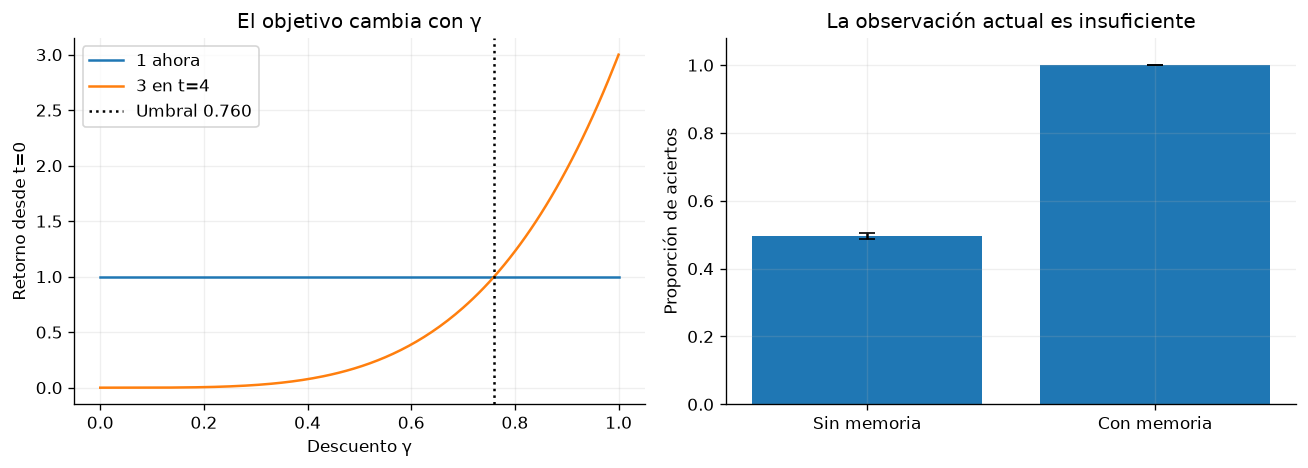

{
  "umbral_gamma": 0.7598356856515925,
  "episodios_por_replica": 1000,
  "sin_memoria": {
    "media": 0.4955000000000001,
    "ic95_aprox_semianchura": 0.009403593266182321
  },
  "con_memoria": {
    "media": 1.0,
    "ic95_aprox_semianchura": 0.0
  }
}


In [3]:
display(Image(filename=str(carpeta / "figura.png")))
resumen = json.loads((carpeta / "resumen.json").read_text())
print(json.dumps(resumen, indent=2, ensure_ascii=False))

## Inspeccionar los datos

Las claves describen métricas; las dimensiones suelen ser réplica × instante, excepto los arrays auxiliares. Escribe una conclusión que apoyen los datos y una limitación. Prueba la modificación propuesta en el texto; antes de ejecutarla, predice su efecto.

In [4]:
import numpy as np
with np.load(carpeta / "datos.npz") as datos:
    for nombre in datos.files:
        print(nombre, datos[nombre].shape)

gamma (201,)
inmediato (201,)
demorado (201,)
aciertos (20, 2)


## Tu variante

Anota aquí: hipótesis, parámetro cambiado, métrica, resultado y limitación. Para modificar la dinámica o el algoritmo, edita el módulo mostrado o copia su función a una celda y experimenta con ella.

Fuente: [Kevin P. Murphy, Reinforcement Learning: An Overview, v5](https://arxiv.org/abs/2412.05265v5), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Resumen adaptado y experimento propio de esta guía.